Loading Dataset

In [40]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split



In [11]:
file_path = r'C:\Users\mathe\Downloads\archive\Iris.csv' #r is there so python understands that its not code and it is a character - must for all file locations
df = pd.read_csv(file_path)
df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [12]:
#delete Id coloumn - we don't need it
df = df.drop(columns = ['Id'])
df.head()


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [13]:
#displaying some statistics about the data
df.describe()


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [15]:
#to know what kind of datatype
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   SepalLengthCm  150 non-null    float64
 1   SepalWidthCm   150 non-null    float64
 2   PetalLengthCm  150 non-null    float64
 3   PetalWidthCm   150 non-null    float64
 4   Species        150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


In [21]:
#to display number of species types (to know how many classes)
df['Species'].value_counts()

Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64

Pre Processing the Data

In [25]:
#check for null values
df.isnull().sum() #without sum all of them is displayed

SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64

Data Analysis

<Axes: >

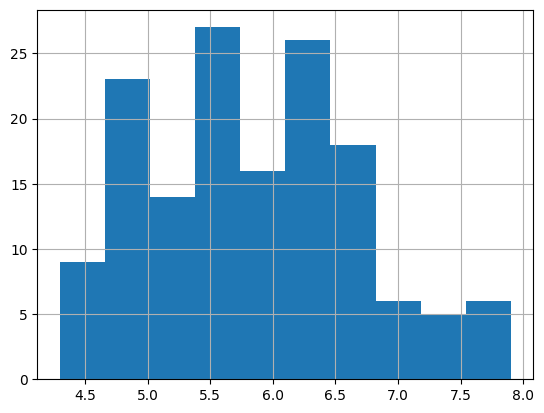

In [26]:
df['SepalLengthCm'].hist() 

<Axes: >

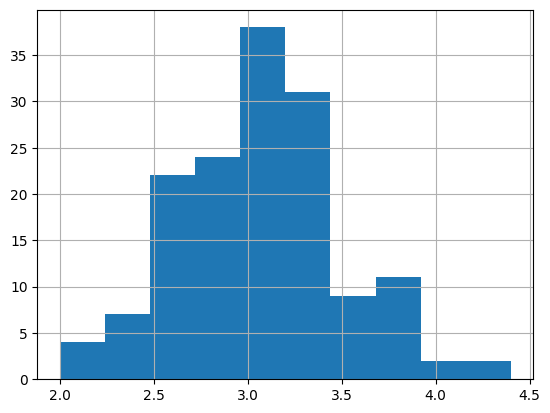

In [27]:
df['SepalWidthCm'].hist() #why are we doing this - to see what kind of data distribution it is - it is normal - inductive bias

<Axes: >

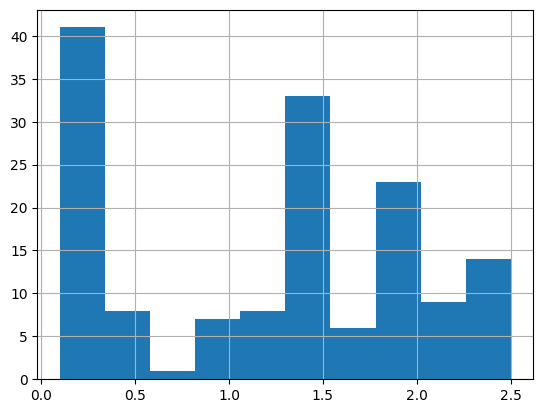

In [28]:
df['PetalWidthCm'].hist()

<Axes: >

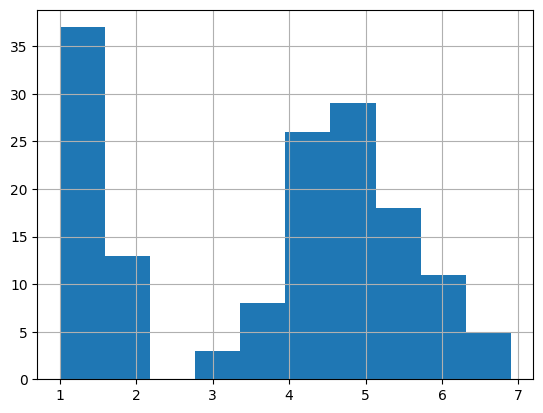

In [29]:
df['PetalLengthCm'].hist()

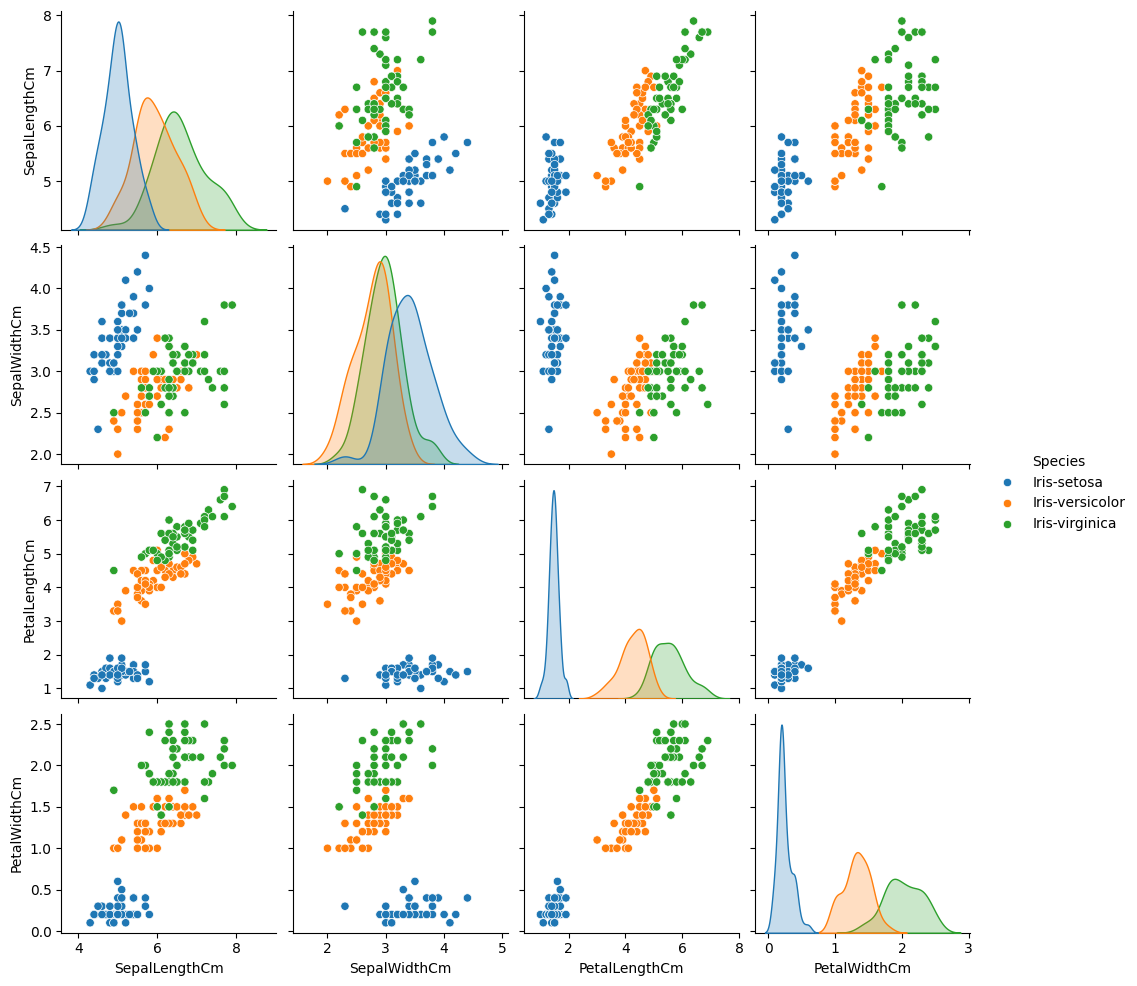

In [39]:
import warnings
warnings.filterwarnings("ignore")
sns.pairplot(df, hue='Species')
plt.show()

Correlation Matrix - correlation coefficients for these variables

In [55]:
X = df.drop('Species',axis=1)
y = df['Species']
X_train,X_test,y_train,y_test = train_test_split(
    X,y,
    test_size=0.25,
    random_state=12)

In [56]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Logistic Regression

In [57]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

lr = LogisticRegression(max_iter=200)
lr.fit(X_train_scaled, y_train)

y_pred_lr = lr.predict(X_test_scaled)
print("Logistic Regression Accuracy:", accuracy_score(y_test, y_pred_lr))
print(classification_report(y_test, y_pred_lr))

Logistic Regression Accuracy: 0.9736842105263158
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        15
Iris-versicolor       1.00      0.92      0.96        12
 Iris-virginica       0.92      1.00      0.96        11

       accuracy                           0.97        38
      macro avg       0.97      0.97      0.97        38
   weighted avg       0.98      0.97      0.97        38



K Neighbours

In [58]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

y_pred_knn = knn.predict(X_test_scaled)
print("KNN Accuracy:", accuracy_score(y_test, y_pred_knn))
print(classification_report(y_test, y_pred_knn))

KNN Accuracy: 0.9473684210526315
                 precision    recall  f1-score   support

    Iris-setosa       1.00      0.93      0.97        15
Iris-versicolor       0.92      0.92      0.92        12
 Iris-virginica       0.92      1.00      0.96        11

       accuracy                           0.95        38
      macro avg       0.94      0.95      0.95        38
   weighted avg       0.95      0.95      0.95        38



Support Vector Machine

In [59]:
from sklearn.svm import SVC

svm = SVC(kernel='rbf', gamma='scale')
svm.fit(X_train_scaled, y_train)

y_pred_svm = svm.predict(X_test_scaled)
print("SVM Accuracy:", accuracy_score(y_test, y_pred_svm))
print(classification_report(y_test, y_pred_svm))

SVM Accuracy: 0.9736842105263158
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        15
Iris-versicolor       1.00      0.92      0.96        12
 Iris-virginica       0.92      1.00      0.96        11

       accuracy                           0.97        38
      macro avg       0.97      0.97      0.97        38
   weighted avg       0.98      0.97      0.97        38



Random Forest Classifier

In [60]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)
print("Random Forest Accuracy:", accuracy_score(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf))

Random Forest Accuracy: 0.9473684210526315
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        15
Iris-versicolor       1.00      0.83      0.91        12
 Iris-virginica       0.85      1.00      0.92        11

       accuracy                           0.95        38
      macro avg       0.95      0.94      0.94        38
   weighted avg       0.96      0.95      0.95        38



#next ones are focused on CART and AdaBoost (Tree Based), Naive Bayes and Bayesian Logistic Regression (Probabilistic Classification)


CART Decision Tree

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        15
Iris-versicolor       1.00      0.83      0.91        12
 Iris-virginica       0.85      1.00      0.92        11

       accuracy                           0.95        38
      macro avg       0.95      0.94      0.94        38
   weighted avg       0.96      0.95      0.95        38

[[15  0  0]
 [ 0 10  2]
 [ 0  0 11]]


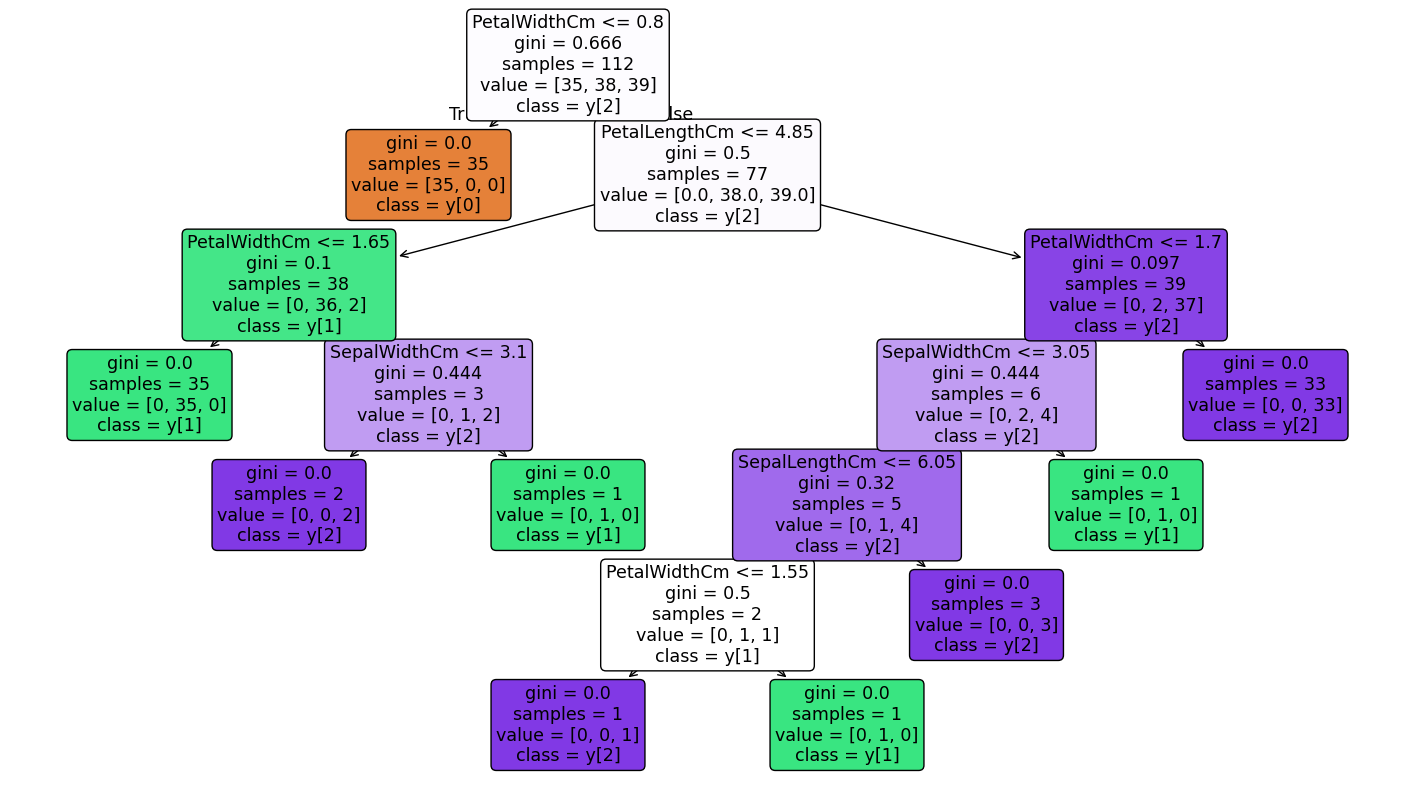

In [70]:
from sklearn.tree import DecisionTreeClassifier 
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt


#information from ISLR or ISL Python - SLDS Coursebook
cart = DecisionTreeClassifier(
    criterion="gini",      # or "entropy"
    max_depth=None,        # control tree depth
    min_samples_split=2,   # minimum samples to split a node
    min_samples_leaf=1,    # minimum samples at a leaf
    max_features=None,     # number of features to consider at split
    random_state=16
)

cart.fit(X_train, y_train)
y_pred = cart.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))


plt.figure(figsize=(18,10))
plot_tree(
    cart,
    feature_names=X.columns,
    class_names=True,
    filled=True,
    rounded=True
)
plt.show()


In [78]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier

base_learner = DecisionTreeClassifier(
    max_depth=1,          # decision stump (standard for AdaBoost)
    random_state=42
)

ada = AdaBoostClassifier(
    estimator=base_learner,   # weak learner
    n_estimators=100,         # number of weak learners
    learning_rate=1.0,        # shrinkage
    random_state=12
)

ada.fit(X_train,y_train)
y_pred = ada.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

#key difference between random forests and Adaboost - random forests have elements of stochasticity while Adaboost does not, hence changing the randomseed value will have different effects in different places. what is the element of stochasticity in random forests
#random forests focus on random features
#how?
#cart - chooses the best feature to split on, adaboost - makes many trees and the mistakes are always weighted the same way, random forests - bootstraps the sample - hence the input sample gives you stochasticity - enabling randomness hence the random in random forests :D

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        15
Iris-versicolor       1.00      0.92      0.96        12
 Iris-virginica       0.92      1.00      0.96        11

       accuracy                           0.97        38
      macro avg       0.97      0.97      0.97        38
   weighted avg       0.98      0.97      0.97        38

[[15  0  0]
 [ 0 11  1]
 [ 0  0 11]]
